In [1]:
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import plotly.express as px
import folium

from tqdm import tqdm
from pathlib import Path


In [2]:
#| echo: true
CITIBIKE_INDEX_URL = "https://s3.amazonaws.com/tripdata"
OUTPUT_DIR = "../data/citibike"
PERIOD = "202510"


In [3]:
# eval: true
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

file_name = f"JC-{PERIOD}-citibike-tripdata.zip"

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(exist_ok=True)

zip_path = output_dir / file_name


## Dowloading the Zip file
url = f"{CITIBIKE_INDEX_URL}/{file_name}"

print(f"Downloading: {url}")
urlretrieve(url, zip_path)

print(f"Saved ZIP file to: {zip_path}")


with ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(output_dir)

print(f"Extracted files into: {output_dir}")

Downloading: https://s3.amazonaws.com/tripdata/JC-202510-citibike-tripdata.zip


Saved ZIP file to: ..\data\citibike\JC-202510-citibike-tripdata.zip
Extracted files into: ..\data\citibike


In [4]:
zip_path.unlink()
print("ZIP file removed.")

ZIP file removed.


In [5]:
file_name  = 'JC-202510-citibike-tripdata.csv'
citibike_202510 = pd.read_csv(f'{output_dir}/{file_name}')
citibike_202510.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,929852F0DC04F49C,electric_bike,2025-10-08 06:59:53.767,2025-10-08 07:04:08.012,Warren St,JC006,Essex Light Rail,NaN,40.721124,-74.038051,NaN,NaN,member
1,7E6F8FADF45B1D8E,electric_bike,2025-10-08 08:13:15.096,2025-10-08 08:18:16.168,Newark Ave,JC032,Essex Light Rail,NaN,40.721525,-74.046305,NaN,NaN,member
2,9B679869FCA8F845,electric_bike,2025-10-09 10:10:26.020,2025-10-09 10:20:08.505,Liberty Light Rail,JC052,Newport PATH,NaN,40.711242,-74.055701,NaN,NaN,member
3,E2051DD457BC4076,electric_bike,2025-10-09 11:34:22.937,2025-10-09 11:48:49.501,Hoboken Ave at Monmouth St,JC105,Newport PATH,NaN,40.735208,-74.046964,NaN,NaN,member
4,239AC07371E414EC,electric_bike,2025-10-23 19:24:16.237,2025-10-23 19:28:22.592,Union St & Bergen Ave,JC122,Garfield Light Rail,JC119,40.715750,-74.078870,40.710526,-74.070112,member


In [6]:
def period_iterator(year:list,start_m:int, stop_m:int)->list:
    """
    
    """
    YEAR = year
    MONTH =  [str(i+1) if i+1>9 else "0" + str(i+1) for i in range(start_m, stop_m)]

    periods = []

    for i in YEAR:
        for j in MONTH:
            k = i+j
            periods.append(k)
    # print(periods)
    return periods

In [7]:
periods  = period_iterator(year = ['2025'],start_m = 0, stop_m = 12)

periods

['202501',
 '202502',
 '202503',
 '202504',
 '202505',
 '202506',
 '202507',
 '202508',
 '202509',
 '202510',
 '202511',
 '202512']

In [8]:
#| echo: true
#| eval: true
#| output: true
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

BASE_URL = "https://s3.amazonaws.com/tripdata"
OUTPUT_DIR = "../data/citibike"
output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(exist_ok=True)

periods = periods

print(periods)
for  period in periods:
    file_name = f"JC-{period}-citibike-tripdata.csv.zip"


    zip_path = output_dir / file_name
    url = f"{BASE_URL}/{file_name}"

    print("downloading form:  ", url)
    
    urlretrieve(url,zip_path)
    
    print("saving into:  ", zip_path)


    with ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(output_dir)


    print(f"Extracted files into: {output_dir}")

    zip_path.unlink()
    print("ZIP file removed.")


['202501', '202502', '202503', '202504', '202505', '202506', '202507', '202508', '202509', '202510', '202511', '202512']
downloading form:   https://s3.amazonaws.com/tripdata/JC-202501-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202501-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.
downloading form:   https://s3.amazonaws.com/tripdata/JC-202502-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202502-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.
downloading form:   https://s3.amazonaws.com/tripdata/JC-202503-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202503-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.
downloading form:   https://s3.amazonaws.com/tripdata/JC-202504-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202504-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.
downloading form:  

HTTPError: HTTP Error 404: Not Found

In [9]:
def download_periods(year:list,start_m:int, stop_m:int)->list:
    """
    
    """
    YEAR = year
    MONTH =  [str(i+1) if i+1>9 else "0" + str(i+1) for i in range(start_m, stop_m)]

    periods = []

    for i in YEAR:
        for j in MONTH:
            k = i+j
            periods.append(k)
    print(periods)
    return periods

In [10]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

BASE_URL = "https://s3.amazonaws.com/tripdata"
OUTPUT_DIR = "../data/citibike"
output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(exist_ok=True)

periods = download_periods(['2025'],10,12)

print(periods)
for  period in periods:
    file_name = f"JC-{period}-citibike-tripdata.csv.zip"


    zip_path = output_dir / file_name
    url = f"{BASE_URL}/{file_name}"

    print("downloading form:  ", url)
    
    urlretrieve(url,zip_path)
    
    print("saving into:  ", zip_path)


    with ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(output_dir)


    print(f"Extracted files into: {output_dir}")

    zip_path.unlink()
    print("ZIP file removed.")

['202511', '202512']
['202511', '202512']
downloading form:   https://s3.amazonaws.com/tripdata/JC-202511-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202511-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.
downloading form:   https://s3.amazonaws.com/tripdata/JC-202512-citibike-tripdata.csv.zip
saving into:   ..\data\citibike\JC-202512-citibike-tripdata.csv.zip
Extracted files into: ..\data\citibike
ZIP file removed.


In [11]:
import glob
import numpy as np
import pandas as pd

file_names = glob.glob(f'{output_dir}/*.csv')



dfs = []
cols = []
for file_name in file_names:
    df = pd.read_csv(file_name)
    print(df.columns, 2*"||",len(df.columns))

    cols.append(list(df.columns))
    dfs.append(df)

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      d

In [12]:
citibike_df = pd.concat(dfs)
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member


In [13]:
citibike_df['started_at'] = pd.to_datetime(df['started_at'])
citibike_df['ended_at'] = pd.to_datetime(df['ended_at'])

In [14]:
citibike_df.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str')

In [15]:
missing_values = (
    citibike_df
    .isna()
    .sum()
    .reset_index()
)

missing_values.columns = ["column", "missing_count"]

missing_values["missing_share"] = (
    missing_values["missing_count"] / len(citibike_df)
)

missing_values.sort_values("missing_count", ascending=False)

,column,missing_count,missing_share
2,started_at,424235,0.423091
3,ended_at,424235,0.423091
7,end_station_id,4397,0.004385
10,end_lat,3444,0.003435
11,end_lng,3444,0.003435
6,end_station_name,3235,0.003226
5,start_station_id,3,0.000003
4,start_station_name,3,0.000003
8,start_lat,2,0.000002
9,start_lng,2,0.000002


In [16]:
citibike_df["ride_duration_minutes"] = (
    citibike_df["ended_at"] - citibike_df["started_at"]
).dt.total_seconds() / 60

In [17]:
citibike_df = citibike_df.dropna(
    subset=[
        "ride_id",
        "started_at",
        "ended_at",
        "start_lat",
        "start_lng",
        "end_lat",
        "end_lng"
    ]
)

citibike_df = citibike_df[
    (citibike_df["ride_duration_minutes"] > 1) &
    (citibike_df["ride_duration_minutes"] <= 24 * 60)
].copy()

In [18]:
citibike_df["date"] = citibike_df["started_at"].dt.date
citibike_df["month"] = citibike_df["started_at"].dt.to_period("M").astype(str)
citibike_df["month_name"] = citibike_df["started_at"].dt.month_name()
citibike_df["day_of_week"] = citibike_df["started_at"].dt.day_name()
citibike_df["hour"] = citibike_df["started_at"].dt.hour

In [19]:
def assign_season(month_number):
    if month_number in [12, 1, 2]:
        return "Winter"
    elif month_number in [3, 4, 5]:
        return "Spring"
    elif month_number in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


citibike_df["season"] = (
    citibike_df["started_at"]
    .dt.month
    .apply(assign_season)
)

In [20]:
citibike_df[
    [
        "started_at",
        "date",
        "month",
        "month_name",
        "day_of_week",
        "hour",
        "season"
    ]
].head()

,started_at,date,month,month_name,day_of_week,hour,season
0,2025-12-26 10:20:09.188,2025-12-26,2025-12,December,Friday,10,Winter
1,2025-12-16 06:48:28.111,2025-12-16,2025-12,December,Tuesday,6,Winter
2,2025-12-20 12:50:55.361,2025-12-20,2025-12,December,Saturday,12,Winter
3,2025-12-22 16:59:42.922,2025-12-22,2025-12,December,Monday,16,Winter
4,2025-12-17 18:06:09.352,2025-12-17,2025-12,December,Wednesday,18,Winter


In [21]:
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes,date,month,month_name,day_of_week,hour,season
0,880A0159BA5275FB,electric_bike,2025-12-26 10:20:09.188,2025-12-26 10:40:13.508,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,20.072000,2025-12-26,2025-12,December,Friday,10,Winter
1,1A5E1E274B2AF0AD,electric_bike,2025-12-16 06:48:28.111,2025-12-16 06:56:10.969,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,7.714300,2025-12-16,2025-12,December,Tuesday,6,Winter
2,EA9928D3C05B8377,classic_bike,2025-12-20 12:50:55.361,2025-12-20 12:58:32.234,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,7.614550,2025-12-20,2025-12,December,Saturday,12,Winter
3,3C42C367750B9292,electric_bike,2025-12-22 16:59:42.922,2025-12-22 17:04:29.327,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,4.773417,2025-12-22,2025-12,December,Monday,16,Winter
4,94D3B0265A7BDE1F,classic_bike,2025-12-17 18:06:09.352,2025-12-17 18:14:13.548,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,8.069933,2025-12-17,2025-12,December,Wednesday,18,Winter


In [22]:
uniq_values = citibike_df["month"].unique()

In [23]:
print(uniq_values)

<ArrowStringArray>
['2025-12', '2025-11']
Length: 2, dtype: str


In [24]:
import pandas as pd
import requests

lat = 40.7178
lng = -74.0431

start_date = "2025-01-01"
end_date = "2025-12-31"

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lng,
    "start_date": start_date,
    "end_date": end_date,
    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "precipitation_sum",
        "rain_sum",
        "snowfall_sum",
        "wind_speed_10m_max"
    ],
    "timezone": "America/New_York"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

weather_daily = pd.DataFrame(data["daily"])
weather_daily["date"] = pd.to_datetime(weather_daily["time"])
weather_daily = weather_daily.drop(columns="time")

weather_daily.head()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,date
0,10.9,3.9,7.4,4.5,4.5,0.0,23.2,2025-01-01
1,5.4,0.3,2.6,0.0,0.0,0.0,25.1,2025-01-02
2,3.2,-1.9,0.4,0.0,0.0,0.0,17.1,2025-01-03
3,-0.1,-2.7,-1.4,0.0,0.0,0.0,26.1,2025-01-04
4,0.3,-3.6,-2.2,0.0,0.0,0.0,19.9,2025-01-05


In [25]:
citibike_df[
    [
        "started_at",
        "date",
        "month",
        "month_name",
        "day_of_week",
        "hour",
        "season"
    ]
].head()

,started_at,date,month,month_name,day_of_week,hour,season
0,2025-12-26 10:20:09.188,2025-12-26,2025-12,December,Friday,10,Winter
1,2025-12-16 06:48:28.111,2025-12-16,2025-12,December,Tuesday,6,Winter
2,2025-12-20 12:50:55.361,2025-12-20,2025-12,December,Saturday,12,Winter
3,2025-12-22 16:59:42.922,2025-12-22,2025-12,December,Monday,16,Winter
4,2025-12-17 18:06:09.352,2025-12-17,2025-12,December,Wednesday,18,Winter


In [26]:
trips_per_month = (
    citibike_df
    .groupby("month")
    .size()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

trips_per_month

,month,trip_count
1,2025-12,575617
0,2025-11,24


In [27]:
trips_per_month = (
    citibike_df
    .groupby("month")["started_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

trips_per_month

,month,trip_count
1,2025-12,575617
0,2025-11,24


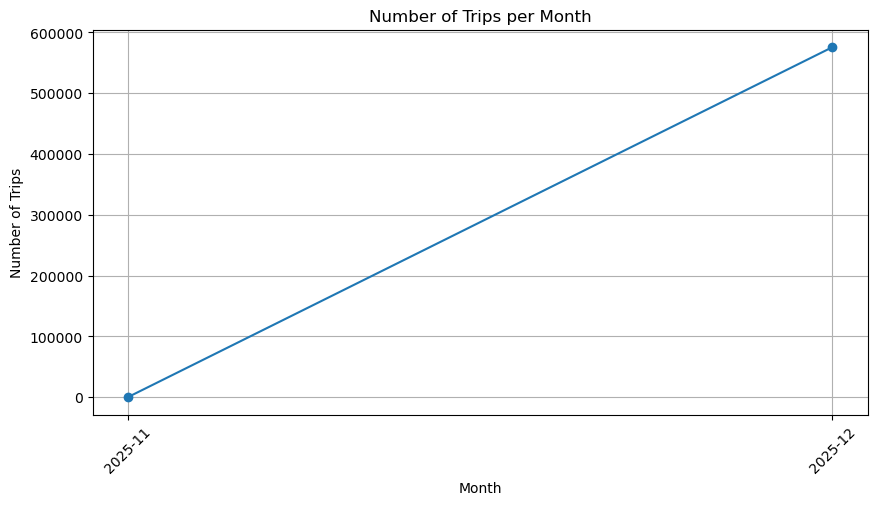

In [28]:
import matplotlib.pyplot as plt

trips_per_month = (
    citibike_df
    .groupby("month")["started_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("month")
)

plt.figure(figsize=(10, 5))

plt.plot(
    trips_per_month["month"].astype(str),
    trips_per_month["trip_count"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.title("Number of Trips per Month")

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [29]:
trips_per_month = (
    citibike_df
    .groupby("month")["started_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

trips_per_month

,month,trip_count
1,2025-12,575617
0,2025-11,24


In [30]:
fig = px.line(
    trips_per_month,
    x="month",
    y="trip_count",
    markers=True,
    title="Monthly number of trips"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="trip_count"
)

fig.show()

In [31]:
trips_per_season = (
    citibike_df
    .groupby("season")["started_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

trips_per_season

,season,trip_count
1,Winter,575617
0,Autumn,24


In [32]:
fig = px.bar(
    trips_per_season,
    x="season",
    y="trip_count",
    text="trip_count",
    title="Trips_per_season"
)

fig.update_traces(textposition="outside")
fig.update_layout(
    xaxis_title="season",
    yaxis_title="trip_count"
)

fig.show()

In [33]:
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes,date,month,month_name,day_of_week,hour,season
0,880A0159BA5275FB,electric_bike,2025-12-26 10:20:09.188,2025-12-26 10:40:13.508,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,20.072000,2025-12-26,2025-12,December,Friday,10,Winter
1,1A5E1E274B2AF0AD,electric_bike,2025-12-16 06:48:28.111,2025-12-16 06:56:10.969,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,7.714300,2025-12-16,2025-12,December,Tuesday,6,Winter
2,EA9928D3C05B8377,classic_bike,2025-12-20 12:50:55.361,2025-12-20 12:58:32.234,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,7.614550,2025-12-20,2025-12,December,Saturday,12,Winter
3,3C42C367750B9292,electric_bike,2025-12-22 16:59:42.922,2025-12-22 17:04:29.327,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,4.773417,2025-12-22,2025-12,December,Monday,16,Winter
4,94D3B0265A7BDE1F,classic_bike,2025-12-17 18:06:09.352,2025-12-17 18:14:13.548,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,8.069933,2025-12-17,2025-12,December,Wednesday,18,Winter


In [34]:
end_station_name = (
    citibike_df
    .groupby("end_station_name")["ended_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
    
)

end_station_name

,end_station_name,trip_count
192,Grove St PATH,20279
193,Hamilton Park,17244
66,Bergen Ave & Sip Ave,14777
267,Newport PATH,14583
234,Madison St & 1 St,13831
...,...,...
27,6 Ave & Broome St,1
28,6 Ave & Canal St,1
370,W 54 St & 6 Ave,1
372,W 56 St & 10 Ave,1


In [35]:
end_station_name_top_10 = end_station_name.head(10)
print(end_station_name_top_10)

                             end_station_name  trip_count
192                             Grove St PATH       20279
193                             Hamilton Park       17244
66                       Bergen Ave & Sip Ave       14777
267                              Newport PATH       14583
234                         Madison St & 1 St       13831
199  Hoboken Terminal - Hudson St & Hudson Pl       13420
294                           River St & 1 St       12889
8           14 St Ferry - 14 St & Shipyard Ln       11904
109          City Hall - Washington St & 1 St       10979
198                Hoboken Ave at Monmouth St       10841


In [36]:
fig = px.bar(
    end_station_name_top_10,
    x="end_station_name",
    y="trip_count",
    text="trip_count",
    title="end_station_name_top_10"
)

fig.update_traces(textposition="outside")
fig.update_layout(
    xaxis_title="end_station_name",
    yaxis_title="trip_count"
)

fig.show()

In [37]:
start_station_name = (
    citibike_df
    .groupby("start_station_name")["started_at"]
    .count()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
    
)

start_station_name

,start_station_name,trip_count
52,Grove St PATH,24874
58,Hoboken Terminal - Hudson St & Hudson Pl,15168
18,Bergen Ave & Sip Ave,14124
53,Hamilton Park,13963
86,Newport PATH,13583
...,...,...
93,Richard St Light Rail,7
37,Danforth Ave & JFK Blvd,6
69,MLK Dr & Bayview Ave,6
102,Van Nostrand Ave & Ocean Ave,6


In [38]:
start_station_name_top_10 = start_station_name.head(10)
print(start_station_name_top_10)

                          start_station_name  trip_count
52                             Grove St PATH       24874
58  Hoboken Terminal - Hudson St & Hudson Pl       15168
18                      Bergen Ave & Sip Ave       14124
53                             Hamilton Park       13963
86                              Newport PATH       13583
44                               Exchange Pl       11725
59   Hoboken Terminal - River St & Hudson Pl       11634
28          City Hall - Washington St & 1 St       11564
94                           River St & 1 St       10901
33         Columbus Park - Clinton St & 9 St       10695


In [39]:
fig = px.bar(
    start_station_name_top_10,
    x="start_station_name",
    y="trip_count",
    text="trip_count",
    title="start_station_name_top_10"
)

fig.update_traces(textposition="outside")
fig.update_layout(
    xaxis_title="start_station_name",
    yaxis_title="trip_count"
)

fig.show()

In [40]:
weather_daily.head()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,date
0,10.9,3.9,7.4,4.5,4.5,0.0,23.2,2025-01-01
1,5.4,0.3,2.6,0.0,0.0,0.0,25.1,2025-01-02
2,3.2,-1.9,0.4,0.0,0.0,0.0,17.1,2025-01-03
3,-0.1,-2.7,-1.4,0.0,0.0,0.0,26.1,2025-01-04
4,0.3,-3.6,-2.2,0.0,0.0,0.0,19.9,2025-01-05


In [41]:
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes,date,month,month_name,day_of_week,hour,season
0,880A0159BA5275FB,electric_bike,2025-12-26 10:20:09.188,2025-12-26 10:40:13.508,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,20.072000,2025-12-26,2025-12,December,Friday,10,Winter
1,1A5E1E274B2AF0AD,electric_bike,2025-12-16 06:48:28.111,2025-12-16 06:56:10.969,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,7.714300,2025-12-16,2025-12,December,Tuesday,6,Winter
2,EA9928D3C05B8377,classic_bike,2025-12-20 12:50:55.361,2025-12-20 12:58:32.234,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,7.614550,2025-12-20,2025-12,December,Saturday,12,Winter
3,3C42C367750B9292,electric_bike,2025-12-22 16:59:42.922,2025-12-22 17:04:29.327,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,4.773417,2025-12-22,2025-12,December,Monday,16,Winter
4,94D3B0265A7BDE1F,classic_bike,2025-12-17 18:06:09.352,2025-12-17 18:14:13.548,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,8.069933,2025-12-17,2025-12,December,Wednesday,18,Winter


In [42]:
citibike_df['date'] = pd.to_datetime(citibike_df['date'])
weather_daily['date'] = pd.to_datetime(weather_daily['date'])

In [43]:
merged_outer = pd.merge(citibike_df,weather_daily, on = "date", how = "inner")

In [44]:
citibike_weather_daily= merged_outer

In [45]:
citibike_weather_daily

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,day_of_week,hour,season,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,880A0159BA5275FB,electric_bike,2025-12-26 10:20:09.188,2025-12-26 10:40:13.508,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,...,Friday,10,Winter,-2.7,-5.8,-4.1,7.4,0.0,5.18,12.0
1,1A5E1E274B2AF0AD,electric_bike,2025-12-16 06:48:28.111,2025-12-16 06:56:10.969,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,...,Tuesday,6,Winter,-2.3,-9.3,-5.6,0.0,0.0,0.00,11.7
2,EA9928D3C05B8377,classic_bike,2025-12-20 12:50:55.361,2025-12-20 12:58:32.234,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,...,Saturday,12,Winter,2.5,-2.1,-0.1,0.0,0.0,0.00,18.9
3,3C42C367750B9292,electric_bike,2025-12-22 16:59:42.922,2025-12-22 17:04:29.327,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,...,Monday,16,Winter,3.1,-3.0,-0.6,0.0,0.0,0.00,14.1
4,94D3B0265A7BDE1F,classic_bike,2025-12-17 18:06:09.352,2025-12-17 18:14:13.548,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,...,Wednesday,18,Winter,4.3,-6.4,-0.6,0.0,0.0,0.00,14.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
575636,56D74535493E0013,electric_bike,2025-12-23 10:27:20.255,2025-12-23 10:39:19.300,Christ Hospital,JC034,4 St & River St,HB611,40.734786,-74.050444,...,Tuesday,10,Winter,3.1,0.2,1.4,2.9,0.8,1.47,10.8
575637,78AF7D2BDF1F54A0,classic_bike,2025-12-20 11:13:22.773,2025-12-20 11:26:41.150,Christ Hospital,JC034,4 St & River St,HB611,40.734786,-74.050444,...,Saturday,11,Winter,2.5,-2.1,-0.1,0.0,0.0,0.00,18.9
575638,774E8E39F0D74488,classic_bike,2025-12-19 20:49:37.159,2025-12-19 20:55:47.633,Hoboken Terminal - Hudson St & Hudson Pl,HB101,8 St & Washington St,HB603,40.735938,-74.030305,...,Friday,20,Winter,14.5,-0.4,9.0,26.2,26.2,0.00,30.6
575639,DEAB98A7DAC4AC0E,electric_bike,2025-12-12 15:52:15.914,2025-12-12 15:55:56.343,Hoboken Terminal - Hudson St & Hudson Pl,HB101,8 St & Washington St,HB603,40.735938,-74.030305,...,Friday,15,Winter,1.5,-4.8,-1.9,0.0,0.0,0.00,16.1


In [46]:
weather = (
    citibike_weather_daily
    .groupby("temperature_2m_mean")
             ["started_at"]
    .count()
    .reset_index(name="trip_count_weather")
    .sort_values("temperature_2m_mean",
                  ascending=False)
    
)

weather

,temperature_2m_mean,trip_count_weather
29,9.0,17474
28,3.5,11599
27,3.4,13380
26,3.2,29333
25,2.8,24
24,2.5,24364
23,2.4,15893
22,2.0,5766
21,1.6,26644
20,1.5,21368


In [54]:
import pandas as pd
URL = "https://raw.githubusercontent.com/hovhannisyan91/data_analytics_with_python/refs/heads/main/data/citibike"
PATH  = '../data/citibike'
csv_files = csv_files = [
'JC-202511-citibike-tripdata.csv',
 'JC-202507-citibike-tripdata.csv',
 'JC-202505-citibike-tripdata.csv',
 'JC-202503-citibike-tripdata.csv',
 'JC-202509-citibike-tripdata.csv',
 'JC-202501-citibike-tripdata.csv',
 'JC-202506-citibike-tripdata.csv',
 'JC-202510-citibike-tripdata.csv',
 'JC-202504-citibike-tripdata.csv',
 'JC-202512-citibike-tripdata.csv',
 'JC-202502-citibike-tripdata.csv',
 'JC-202508-citibike-tripdata.csv']


for i in csv_files:
    df = pd.read_csv(f"{URL}/{i}")
    df.to_csv(f"{PATH}/{i}", index=False)
    # print(f"{URL} saved in {URLpath} | shape: {df.shape}")

In [55]:
import glob
import numpy as np
import pandas as pd

file_names = glob.glob('../data/citibike/*.csv')



dfs = []
cols = []
for file_name in file_names:
    df = pd.read_csv(file_name)
    print(file_name)
    print(df.columns, 2*"||",len(df.columns))

    cols.append(list(df.columns))
    dfs.append(df)

../data/citibike\JC-202501-citibike-tripdata.csv
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
../data/citibike\JC-202502-citibike-tripdata.csv
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
../data/citibike\JC-202503-citibike-tripdata.csv
Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str') |||| 13
../data/citibike\JC-202504-citibike-tripdata.csv
Index(['ride_id', 'rideable_type', 'sta

In [56]:
citibike_df = pd.concat(dfs)
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member


In [57]:
citibike_df.shape

(1002704, 13)

In [58]:
citibike_df['started_at'] = pd.to_datetime(citibike_df['started_at'],errors="coerce")
citibike_df['ended_at'] = pd.to_datetime(citibike_df['ended_at'],errors="coerce")

citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member


In [61]:
citibike_df.info()

<class 'pandas.DataFrame'>
Index: 1002704 entries, 0 to 48473
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   ride_id             1002704 non-null  str           
 1   rideable_type       1002704 non-null  str           
 2   started_at          1002704 non-null  datetime64[us]
 3   ended_at            1002704 non-null  datetime64[us]
 4   start_station_name  1002701 non-null  str           
 5   start_station_id    1002701 non-null  str           
 6   end_station_name    999469 non-null   str           
 7   end_station_id      998307 non-null   str           
 8   start_lat           1002702 non-null  float64       
 9   start_lng           1002702 non-null  float64       
 10  end_lat             999260 non-null   float64       
 11  end_lng             999260 non-null   float64       
 12  member_casual       1002704 non-null  str           
dtypes: datetime64[us](2), float64(

In [62]:
missing_values = (
    citibike_df
    .isna()
    .sum()
    .reset_index()
)

missing_values.columns = ["column", "missing_count"]

missing_values["missing_share"] = (
    missing_values["missing_count"] / len(citibike_df)
)

missing_values.sort_values("missing_count", ascending=False)

,column,missing_count,missing_share
7,end_station_id,4397,0.004385
10,end_lat,3444,0.003435
11,end_lng,3444,0.003435
6,end_station_name,3235,0.003226
4,start_station_name,3,0.000003
5,start_station_id,3,0.000003
8,start_lat,2,0.000002
9,start_lng,2,0.000002
0,ride_id,0,0.000000
3,ended_at,0,0.000000


In [63]:
citibike_df = citibike_df.dropna(
    subset=[
        "ride_id",
        "started_at",
        "ended_at",
        "start_lat",
        "start_lng",
        "end_lat",
        "end_lng"
    ]
)

In [65]:
citibike_df.shape

(999258, 13)

In [66]:
citibike_df["ride_duration_minutes"] = (
    citibike_df["ended_at"] - citibike_df["started_at"]
).dt.total_seconds() / 60

In [67]:
citibike_df = citibike_df[
    (citibike_df["ride_duration_minutes"] > 1) &
    (citibike_df["ride_duration_minutes"] <= 24 * 60)
].copy()

In [68]:
citibike_df.shape

(999225, 14)

In [69]:
citibike_df["date"] = citibike_df["started_at"].dt.date
citibike_df["month"] = citibike_df["started_at"].dt.to_period("M").astype(str)
citibike_df["month_name"] = citibike_df["started_at"].dt.month_name()
citibike_df["day_of_week"] = citibike_df["started_at"].dt.day_name()
citibike_df["hour"] = citibike_df["started_at"].dt.hour

In [70]:
def assign_season(month_number):
    if month_number in [12, 1, 2]:
        return "Winter"
    elif month_number in [3, 4, 5]:
        return "Spring"
    elif month_number in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


citibike_df["season"] = (
    citibike_df["started_at"]
    .dt.month
    .apply(assign_season)
)

In [73]:
citibike_df.to_csv('../data/citibike/JC/JC2025_Enriched.csv', index= False)

In [76]:
citibike_df.shape

(999225, 20)

In [77]:
citibike_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes,date,month,month_name,day_of_week,hour,season
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,6.192900,2025-01-16,2025-01,January,Thursday,17,Winter
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,11.461350,2025-01-31,2025-01,January,Friday,6,Winter
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,21.377617,2025-01-09,2025-01,January,Thursday,16,Winter
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,22.934333,2025-01-21,2025-01,January,Tuesday,16,Winter
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,25.822100,2025-01-30,2025-01,January,Thursday,16,Winter


In [78]:
mothly_rides = (
    citibike_df
    .groupby("month", as_index = False)
    .agg ( number_of_rides = ("ride_id", "count"))
)

In [79]:
mothly_rides

,month,number_of_rides
0,2024-12,2
1,2025-01,50589
2,2025-02,45250
3,2025-03,73277
4,2025-04,81533
5,2025-05,93202
6,2025-06,96736
7,2025-07,107374
8,2025-08,108001
9,2025-09,115580


In [99]:
import pandas as pd
import requests

lat = 40.7178
lng = -74.0431

start_date = "2025-01-01"
end_date = "2025-12-31"

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lng,
    "start_date": start_date,
    "end_date": end_date,
    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "precipitation_sum",
        "rain_sum",
        "snowfall_sum",
        "wind_speed_10m_max"
    ],
    "timezone": "America/New_York"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

weather_daily = pd.DataFrame(data["daily"])
weather_daily["date"] = pd.to_datetime(weather_daily["time"])
weather_daily = weather_daily.drop(columns="time")

weather_daily.tail()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,date
360,-1.0,-7.3,-3.6,5.3,0.4,3.43,16.3,2025-12-27
361,1.0,-11.6,-5.8,0.9,0.9,0.00,9.4,2025-12-28
362,7.3,-1.4,3.5,3.9,3.9,0.00,23.8,2025-12-29
363,-0.2,-3.0,-1.3,0.0,0.0,0.00,25.5,2025-12-30
364,-0.2,-3.7,-2.2,0.0,0.0,0.00,16.5,2025-12-31


In [100]:
weather_daily.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   temperature_2m_max   365 non-null    float64       
 1   temperature_2m_min   365 non-null    float64       
 2   temperature_2m_mean  365 non-null    float64       
 3   precipitation_sum    365 non-null    float64       
 4   rain_sum             365 non-null    float64       
 5   snowfall_sum         365 non-null    float64       
 6   wind_speed_10m_max   365 non-null    float64       
 7   date                 365 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(7)
memory usage: 22.9 KB


In [101]:
list(weather_daily.columns)

['temperature_2m_max',
 'temperature_2m_min',
 'temperature_2m_mean',
 'precipitation_sum',
 'rain_sum',
 'snowfall_sum',
 'wind_speed_10m_max',
 'date']

In [102]:
weather_daily = weather_daily [['date','temperature_2m_max',
 'temperature_2m_min',
 'temperature_2m_mean',
 'precipitation_sum',
 'rain_sum',
 'snowfall_sum',
 'wind_speed_10m_max']]

In [103]:
weather_daily.head()

,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,2025-01-01,10.9,3.9,7.4,4.5,4.5,0.0,23.2
1,2025-01-02,5.4,0.3,2.6,0.0,0.0,0.0,25.1
2,2025-01-03,3.2,-1.9,0.4,0.0,0.0,0.0,17.1
3,2025-01-04,-0.1,-2.7,-1.4,0.0,0.0,0.0,26.1
4,2025-01-05,0.3,-3.6,-2.2,0.0,0.0,0.0,19.9


In [108]:
citibike_df['date'] = pd.to_datetime(citibike_df['date'],errors="coerce")


In [110]:
citibike_df.info()

<class 'pandas.DataFrame'>
Index: 999225 entries, 0 to 48473
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   ride_id                999225 non-null  str           
 1   rideable_type          999225 non-null  str           
 2   started_at             999225 non-null  datetime64[us]
 3   ended_at               999225 non-null  datetime64[us]
 4   start_station_name     999224 non-null  str           
 5   start_station_id       999224 non-null  str           
 6   end_station_name       998439 non-null  str           
 7   end_station_id         998282 non-null  str           
 8   start_lat              999225 non-null  float64       
 9   start_lng              999225 non-null  float64       
 10  end_lat                999225 non-null  float64       
 11  end_lng                999225 non-null  float64       
 12  member_casual          999225 non-null  str           
 13  r

In [119]:
daily_rides = (
    citibike_df
    .groupby("date", as_index=False)
    .agg(
        number_of_rides=("ride_id", "count")
    )
)
daily_rides["date"] = pd.to_datetime(daily_rides["date"])
daily_rides.head()

,date,number_of_rides
0,2024-12-31,2
1,2025-01-01,1179
2,2025-01-02,1710
3,2025-01-03,1770
4,2025-01-04,1337


In [121]:
bike_weather_daily = daily_rides.merge(
    weather_daily,
    on="date",
    how="left"
)
bike_weather_daily

,date,number_of_rides,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,2024-12-31,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-01-01,1179,10.9,3.9,7.4,4.5,4.5,0.00,23.2
2,2025-01-02,1710,5.4,0.3,2.6,0.0,0.0,0.00,25.1
3,2025-01-03,1770,3.2,-1.9,0.4,0.0,0.0,0.00,17.1
4,2025-01-04,1337,-0.1,-2.7,-1.4,0.0,0.0,0.00,26.1
...,...,...,...,...,...,...,...,...,...
361,2025-12-27,287,-1.0,-7.3,-3.6,5.3,0.4,3.43,16.3
362,2025-12-28,488,1.0,-11.6,-5.8,0.9,0.9,0.00,9.4
363,2025-12-29,952,7.3,-1.4,3.5,3.9,3.9,0.00,23.8
364,2025-12-30,1142,-0.2,-3.0,-1.3,0.0,0.0,0.00,25.5


In [122]:
import plotly.express as px
fig = px.line(
    weather_daily,
    x="date",
    y="temperature_2m_mean",
    title="Daily Average Temperature Over Time",
    markers=False
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Average Temperature",
    hovermode="x unified"
)

fig.show()

In [126]:

import plotly.express as px
fig = px.line(
    weather_daily,
    x="date",
    y="wind_speed_10m_max",
    title="Daily Average Temperature Over Time",
    markers=False
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Average Temperature",
    hovermode="x unified"
)

fig.show()




In [123]:
temperature_long = weather_daily.melt(
    id_vars= 'date',
    value_vars =  [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean"
    ],
    var_name =  "temperature_type",
    value_name = "temperature"
)

temperature_long

,date,temperature_type,temperature
0,2025-01-01,temperature_2m_max,10.9
1,2025-01-02,temperature_2m_max,5.4
2,2025-01-03,temperature_2m_max,3.2
3,2025-01-04,temperature_2m_max,-0.1
4,2025-01-05,temperature_2m_max,0.3
...,...,...,...
1090,2025-12-27,temperature_2m_mean,-3.6
1091,2025-12-28,temperature_2m_mean,-5.8
1092,2025-12-29,temperature_2m_mean,3.5
1093,2025-12-30,temperature_2m_mean,-1.3


In [124]:
fig = px.line(
    temperature_long,
    x="date",
    y="temperature",
    color="temperature_type",
    title="Daily Temperature: Maximum, Minimum, and Average",
    markers=False
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Temperature",
    # hovermode="x unified"
)

fig.show()

In [111]:
customers = pd.DataFrame({
    "customer_id": [1, 2, 3, 4],
    "customer_name": ["Anna", "David", "Mariam", "Arman"],
    "city": ["Yerevan", "Gyumri", "Yerevan", "Vanadzor"]
})

orders = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105],
    "customer_id": [1, 2, 2, 3, 5],
    "order_amount": [25000, 18000, 42000, 15000, 30000]
})




In [113]:
pd.merge(customers,orders,how = "inner", on = "customer_id")


,customer_id,customer_name,city,order_id,order_amount
0,1,Anna,Yerevan,101,25000
1,2,David,Gyumri,102,18000
2,2,David,Gyumri,103,42000
3,3,Mariam,Yerevan,104,15000
